# Probabilistic SMS Spam Detection
**BAMAT207 Probability and Statistics — Project Activity**

Topic: Probability and Random Variables · Dataset: UCI SMS Spam Collection

In [1]:
import os, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': 'black', 'axes.labelcolor': 'black',
    'text.color': 'black', 'xtick.color': 'black', 'ytick.color': 'black',
    'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
})
os.makedirs('figures', exist_ok=True)

## Activity 1: Dataset Handling

In [2]:
import glob
import os
import zipfile

# Locate and extract the dataset zip
candidates = (glob.glob('/content/*spam*collection*.zip') + glob.glob('/content/*.zip')
              + glob.glob('*spam*collection*.zip') + glob.glob('*.zip'))
extract_path = 'sms_spam_data'
if not os.path.exists(os.path.join(extract_path, 'SMSSpamCollection')):
    if os.path.exists('SMSSpamCollection'):
        extract_path = '.'
    elif candidates:
        with zipfile.ZipFile(candidates[0]) as z:
            z.extractall(extract_path)
    else:
        raise FileNotFoundError('Upload smsspamcollection.zip (or sms+spam+collection.zip) to the Colab files panel first.')
print('Extracted files:', os.listdir(extract_path))

Extracted files: ['readme', 'SMSSpamCollection']


In [3]:
import pandas as pd
import os

# Load the tab-separated file: label <TAB> message
data_file = os.path.join(extract_path, 'SMSSpamCollection')
try:
    df = pd.read_csv(data_file, sep='\t', names=['label', 'message'], encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv(data_file, sep='\t', names=['label', 'message'], encoding='latin-1')
initial_rows = len(df)

print('Initial shape        :', df.shape)
print('Missing values       :')
print(df.isnull().sum().to_string())

dup_count = df.duplicated(subset=['message']).sum()
df = df.drop_duplicates(subset=['message']).reset_index(drop=True)
print(f'\nDuplicate messages removed: {dup_count}')
print('Shape after cleaning :', df.shape)

# Spam = 1, Ham = 0
df['label_num'] = df['label'].map({'spam': 1, 'ham': 0})
print('\nLabel encoding check :', df['label_num'].isnull().sum(), 'unmapped labels')
df.head()

Initial shape        : (5572, 2)
Missing values       :
label      0
message    0

Duplicate messages removed: 403
Shape after cleaning : (5169, 2)

Label encoding check : 0 unmapped labels


,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [4]:
# Cleaned dataset summary
df['length'] = df['message'].str.len()
df['words'] = df['message'].str.split().str.len()
print('--- Cleaned Dataset Summary ---')
print(f'Rows before cleaning        : {initial_rows}')
print(f'Duplicates removed          : {dup_count}')
print(f'Rows after cleaning         : {len(df)}')
print(f'Missing values              : {int(df.isnull().sum().sum())}')
print(f'Average length (characters) : ham {df[df.label_num==0].length.mean():.1f}, spam {df[df.label_num==1].length.mean():.1f}')
print(f'Average length (words)      : ham {df[df.label_num==0].words.mean():.1f}, spam {df[df.label_num==1].words.mean():.1f}')

--- Cleaned Dataset Summary ---
Rows before cleaning        : 5572
Duplicates removed          : 403
Rows after cleaning         : 5169
Missing values              : 0
Average length (characters) : ham 70.9, spam 137.7
Average length (words)      : ham 14.2, spam 23.7


## Activity 2: Dataset Analysis

Total messages : 5169
Spam messages  : 653   P(Spam) = 653/5169 = 0.1263
Ham messages   : 4516   P(Ham)  = 4516/5169 = 0.8737


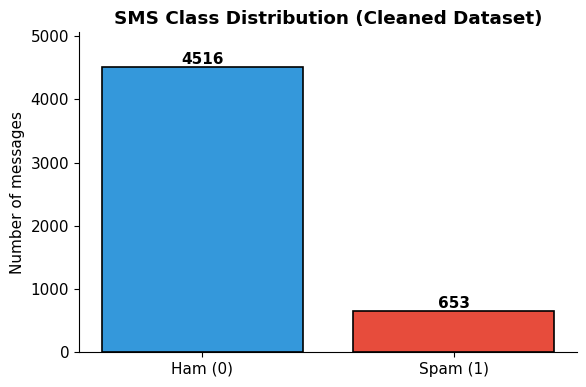

In [5]:
total_messages = len(df)
spam_count = int(df['label_num'].sum())
ham_count = total_messages - spam_count
p_spam = spam_count / total_messages
p_ham = ham_count / total_messages

print(f'Total messages : {total_messages}')
print(f'Spam messages  : {spam_count}   P(Spam) = {spam_count}/{total_messages} = {p_spam:.4f}')
print(f'Ham messages   : {ham_count}   P(Ham)  = {ham_count}/{total_messages} = {p_ham:.4f}')

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Ham (0)', 'Spam (1)'], [ham_count, spam_count],
              color=['#3498db', '#e74c3c'], edgecolor='black', linewidth=1.2)
for b, v in zip(bars, [ham_count, spam_count]):
    ax.text(b.get_x() + b.get_width()/2, v + 40, f'{v}', ha='center', fontweight='bold')
ax.set_title('SMS Class Distribution (Cleaned Dataset)', fontweight='bold')
ax.set_ylabel('Number of messages')
ax.set_ylim(0, ham_count * 1.12)
plt.tight_layout()
plt.savefig('figures/class_distribution.png', dpi=200)
plt.show()

## Activity 3: Word-Based Probability Analysis
For each suspicious word, P(Spam | Word) is computed directly and then verified with Bayes' theorem: P(Spam | Word) = P(Word | Spam) × P(Spam) / P(Word).

Word: 'free'
  Messages containing word      : 203
  Spam messages containing word : 148
  Direct   P(Spam | Free  ) = 148/203 = 0.7291
  Bayes    P(Spam | Free  ) = (0.2266 x 0.1263) / 0.0393 = 0.7291
  Match: True
------------------------------------------------------------
Word: 'prize'
  Messages containing word      : 73
  Spam messages containing word : 73
  Direct   P(Spam | Prize ) = 73/73 = 1.0000
  Bayes    P(Spam | Prize ) = (0.1118 x 0.1263) / 0.0141 = 1.0000
  Match: True
------------------------------------------------------------
Word: 'win'
  Messages containing word      : 55
  Spam messages containing word : 49
  Direct   P(Spam | Win   ) = 49/55 = 0.8909
  Bayes    P(Spam | Win   ) = (0.0750 x 0.1263) / 0.0106 = 0.8909
  Match: True
------------------------------------------------------------
Word: 'urgent'
  Messages containing word      : 62
  Spam messages containing word : 57
  Direct   P(Spam | Urgent) = 57/62 = 0.9194
  Bayes    P(Spam | Urgent) = (0.0873 x 0.1

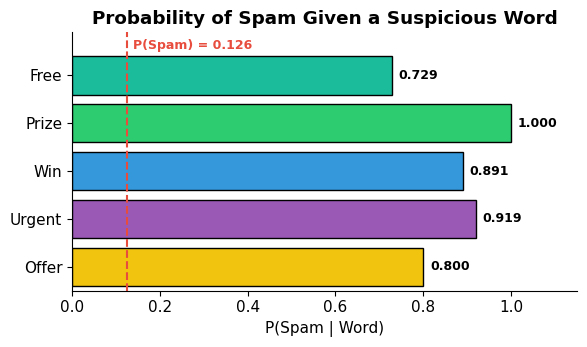

In [6]:
import re
suspicious_words = ['free', 'prize', 'win', 'urgent', 'offer']
lower = df['message'].str.lower()
word_results = []

for word in suspicious_words:
    contains = lower.str.contains(rf'\b{word}\b', regex=True)
    n_word = int(contains.sum())
    n_spam_word = int((contains & (df['label_num'] == 1)).sum())

    p_word = n_word / total_messages
    p_word_given_spam = n_spam_word / spam_count
    direct = n_spam_word / n_word
    bayes = (p_word_given_spam * p_spam) / p_word

    word_results.append((word, n_word, n_spam_word, p_word, p_word_given_spam, direct, bayes))
    print(f"Word: '{word}'")
    print(f'  Messages containing word      : {n_word}')
    print(f'  Spam messages containing word : {n_spam_word}')
    print(f'  Direct   P(Spam | {word.capitalize():6}) = {n_spam_word}/{n_word} = {direct:.4f}')
    print(f'  Bayes    P(Spam | {word.capitalize():6}) = ({p_word_given_spam:.4f} x {p_spam:.4f}) / {p_word:.4f} = {bayes:.4f}')
    print(f'  Match: {np.isclose(direct, bayes)}')
    print('-' * 60)

# Horizontal bar chart of P(Spam | word) with colors
words = [r[0].capitalize() for r in word_results]
probs = [r[5] for r in word_results]
colors = ['#1abc9c', '#2ecc71', '#3498db', '#9b59b6', '#f1c40f']

fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.barh(words[::-1], probs[::-1], color=colors[::-1], edgecolor='black')
ax.axvline(p_spam, color='#e74c3c', linestyle='--', linewidth=1.5)
ax.text(p_spam + 0.012, 4.55, f'P(Spam) = {p_spam:.3f}', fontsize=9, color='#e74c3c', fontweight='bold')
for b, v in zip(bars, probs[::-1]):
    ax.text(v + 0.015, b.get_y() + b.get_height()/2, f'{v:.3f}', va='center', fontsize=9, fontweight='bold')
ax.set_xlim(0, 1.15); ax.set_ylim(-0.5, 4.9)
ax.set_xlabel('P(Spam | Word)')
ax.set_title('Probability of Spam Given a Suspicious Word', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/word_probabilities.png', dpi=200)
plt.show()

## Activity 4: Random Variable Analysis
Let Y = 1 if the message is spam and Y = 0 if it is ham. Y is a Bernoulli random variable with p = P(Spam).

In [7]:
p = p_spam
E_Y = 0 * (1 - p) + 1 * p
Var_Y = p * (1 - p)
# Cross-check with the data itself
print(f'p = P(Spam)        = {p:.4f}')
print(f'E(Y)   = p         = {E_Y:.4f}   (sample mean of Y: {df.label_num.mean():.4f})')
print(f'Var(Y) = p(1 - p)  = {Var_Y:.4f}   (sample variance, population form: {df.label_num.var(ddof=0):.4f})')
print(f'Std. deviation     = {np.sqrt(Var_Y):.4f}')

p = P(Spam)        = 0.1263
E(Y)   = p         = 0.1263   (sample mean of Y: 0.1263)
Var(Y) = p(1 - p)  = 0.1104   (sample variance, population form: 0.1104)
Std. deviation     = 0.3322


## Activity 5: Data Preparation
80 % training, 20 % testing, stratified so that the spam–ham proportion is preserved.

In [8]:
X = df['message']
y = df['label_num']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)   # fit on training data only
X_test_vec = vectorizer.transform(X_test)

print('Training set shape :', X_train_vec.shape)
print('Testing set shape  :', X_test_vec.shape)
print(f'Spam share  full: {y.mean():.4f} | train: {y_train.mean():.4f} | test: {y_test.mean():.4f}')

Training set shape : (4135, 7680)
Testing set shape  : (1034, 7680)
Spam share  full: 0.1263 | train: 0.1262 | test: 0.1267


## Activity 6: Model Building

In [9]:
model = MultinomialNB()
model.fit(X_train_vec, y_train)
print('Multinomial Naive Bayes model trained successfully.')
print('Class priors  P(Ham), P(Spam):', np.exp(model.class_log_prior_).round(4))

Multinomial Naive Bayes model trained successfully.
Class priors  P(Ham), P(Spam): [0.8738 0.1262]


## Activity 7: Model Evaluation

In [10]:
y_pred = model.predict(X_test_vec)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)
cm   = confusion_matrix(y_test, y_pred)

print(f'Accuracy  : {acc:.4f}')
print(f'Precision : {prec:.4f}  (spam class)')
print(f'Recall    : {rec:.4f}  (spam class)')
print(f'F1-score  : {f1:.4f}  (spam class)\n')
print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['Ham (0)', 'Spam (1)'], digits=4))

tn, fp, fn, tp = cm.ravel()
print('Confusion Matrix [rows = true, columns = predicted]:')
print(cm)
print(f'\nTrue Negatives  (ham -> ham)                : {tn}')
print(f'False Positives (genuine classified as spam): {fp}')
print(f'False Negatives (spam classified as genuine): {fn}')
print(f'True Positives  (spam -> spam)              : {tp}')

Accuracy  : 0.9816
Precision : 0.9590  (spam class)
Recall    : 0.8931  (spam class)
F1-score  : 0.9249  (spam class)

Classification Report:
              precision    recall  f1-score   support

     Ham (0)     0.9846    0.9945    0.9895       903
    Spam (1)     0.9590    0.8931    0.9249       131

    accuracy                         0.9816      1034
   macro avg     0.9718    0.9438    0.9572      1034
weighted avg     0.9814    0.9816    0.9813      1034

Confusion Matrix [rows = true, columns = predicted]:
[[898   5]
 [ 14 117]]

True Negatives  (ham -> ham)                : 898
False Positives (genuine classified as spam): 5
False Negatives (spam classified as genuine): 14
True Positives  (spam -> spam)              : 117


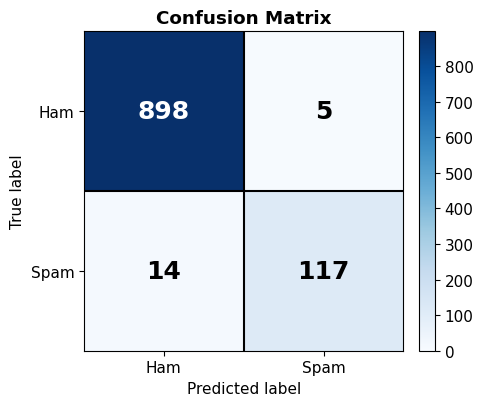

In [11]:
# Confusion matrix with color
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max())
ax.set_xticks([0, 1]); ax.set_xticklabels(['Ham', 'Spam'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['Ham', 'Spam'])
ax.set_xticks([0.5], minor=True); ax.set_yticks([0.5], minor=True)
ax.grid(which='minor', color='black', linewidth=1.5); ax.tick_params(which='minor', length=0)
for i in range(2):
    for j in range(2):
        color = 'white' if cm[i, j] > (cm.max() / 2) else 'black'
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=18, fontweight='bold', color=color)
ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
ax.set_title('Confusion Matrix', fontweight='bold')
for s in ax.spines.values(): s.set_visible(True)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig('figures/confusion_matrix.png', dpi=200)
plt.show()

In [12]:
# Inspect the misclassified messages
test_df = pd.DataFrame({'message': X_test.values, 'true': y_test.values, 'pred': y_pred})
pd.set_option('display.max_colwidth', 140)
print('Spam classified as genuine (False Negatives):')
print(test_df[(test_df.true == 1) & (test_df.pred == 0)]['message'].head(10).to_string(index=False))
print('\nGenuine classified as spam (False Positives):')
print(test_df[(test_df.true == 0) & (test_df.pred == 1)]['message'].head(10).to_string(index=False))

Spam classified as genuine (False Negatives):
Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text stop to stopCost 150p 0...
Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANINExx Calls£1/minMo...
ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAILIFF DUE IN DAYS....
Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x Calls£1/minM...
                                                                    Missed call alert. These numbers called but left no message. 07008009200
                                               SMS. ac sun0819 posts HELLO:"You seem cool, wanted to say hi. HI!!!" Stop? Send STOP to 62468
Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. Ho

In [13]:
# Most spam-indicative and most ham-indicative words (log-probability ratio)
vocab = np.array(vectorizer.get_feature_names_out())
ratio = model.feature_log_prob_[1] - model.feature_log_prob_[0]
print('Top 10 spam-indicative words:', list(vocab[np.argsort(ratio)[::-1][:10]]))
print('Top 10 ham-indicative words :', list(vocab[np.argsort(ratio)[:10]]))

Top 10 spam-indicative words: ['claim', 'prize', '150p', 'tone', 'co', 'www', '18', '500', 'guaranteed', '1000']
Top 10 ham-indicative words : ['gt', 'lt', 'he', 'lor', 'da', 'she', 'later', 'but', 'really', 'doing']


## Activity 8: Real-Time Testing

In [14]:
def predict_message(message):
    vec = vectorizer.transform([message])
    probs = model.predict_proba(vec)[0]          # [P(Ham | msg), P(Spam | msg)]
    label = 'Spam' if probs[1] >= 0.5 else 'Ham'
    print(f'Message: {message}')
    print(f'Prediction: {label}')
    print(f'P(Spam | Message) = {probs[1]:.4f}')
    print(f'P(Ham  | Message) = {probs[0]:.4f}\n')
    return label, probs

# Sample messages (the first is the example in the project brief)
samples = [
    'Congratulations! You have won a free prize. Claim now.',
    'URGENT! Call now to claim your free offer and win a cash prize',
    'Hey, are we still meeting for lunch at 1 pm tomorrow?',
    'Please send me the notes from yesterday class when you are free',
]
for s in samples:
    predict_message(s)

Message: Congratulations! You have won a free prize. Claim now.
Prediction: Spam
P(Spam | Message) = 1.0000
P(Ham  | Message) = 0.0000

Message: URGENT! Call now to claim your free offer and win a cash prize
Prediction: Spam
P(Spam | Message) = 1.0000
P(Ham  | Message) = 0.0000

Message: Hey, are we still meeting for lunch at 1 pm tomorrow?
Prediction: Ham
P(Spam | Message) = 0.0000
P(Ham  | Message) = 1.0000

Message: Please send me the notes from yesterday class when you are free
Prediction: Ham
P(Spam | Message) = 0.0004
P(Ham  | Message) = 0.9996



In [15]:
# Interactive test: type any SMS and press Enter (in Colab a text box appears below this cell)
try:
    user_msg = input('Enter an SMS message to classify: ').strip()
except (EOFError, OSError):
    user_msg = ''
if user_msg:
    predict_message(user_msg)
else:
    print('No input given - type a message and run this cell again.')

Enter an SMS message to classify: Congratulations! You have won a free prize. Claim now.
Message: Congratulations! You have won a free prize. Claim now.
Prediction: Spam
P(Spam | Message) = 1.0000
P(Ham  | Message) = 0.0000



## Summary of Deliverables
- Cleaned dataset summary: Activity 1
- Class-distribution chart: Activity 2
- Probability calculations for five suspicious words, with Bayes verification: Activity 3
- E(Y) and Var(Y): Activity 4
- Trained Multinomial Naive Bayes model: Activity 6
- Confusion matrix and performance report: Activity 7
- Real-time prediction with probabilities: Activity 8

Remember to upload this notebook to a GitHub repository and share the link at submission.